# Данные и сезонность бронирований

В Hotel Booking Demand есть история двух отелей с плановыми заездами с июля 2015 по август 2017. Сначала посмотрю, как меняются число броней и доля отмен по месяцам. Затем определю, какой прогноз можно проверить по этим данным.

Источник: [Antonio, Almeida, Nunes — Hotel booking demand datasets](https://pmc.ncbi.nlm.nih.gov/articles/PMC6297060/). Авторы описывают снимок признаков накануне заезда. Поэтому в этой версии рассматриваю позднюю отмену или незаезд для брони, которая ещё активна вечером перед заездом.

In [1]:
import json
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent
REPORTS = ROOT / "reports/evaluation"
plt.rcParams.update(
    {"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False}
)

In [2]:
quality = json.loads((REPORTS / "data_quality.json").read_text())
pd.Series(quality, name="value").to_frame()

,value
raw_rows,119390
duplicate_rows,31994
same_day_bookings,6345
already_canceled,42137
eligible_rows,70908
late_cancellations,1657
late_cancellation_rate,0.023368
missing_target,0
missing_children,4
zero_guests,180


В исходной таблице 119 390 строк, из них 31 994 полностью совпадают по значениям. Идентификаторов реальных бронирований нет, поэтому одинаковые строки могут относиться к разным гостям или групповой заявке. Такие строки сохраняю. Все брони одной даты заезда попадают в один временной период.

Пропуски и нулевые значения оставляю видимыми в отчёте. В модельной обработке пропущенное число детей заполняется медианой для Logistic Regression; CatBoost принимает числовые NaN.

In [3]:
pd.read_csv(REPORTS / "missingness.csv", index_col=0).query(
    "missing_share > 0"
).sort_values("missing_share", ascending=False)

,missing_share
company,0.943069
agent,0.136862
country,0.004087
children,0.000034


## Число броней и отмены по месяцам

Разделю два отеля: у городского и курортного отеля разный объём и сезонный рисунок. На первом графике учитываются все брони с плановым заездом в месяце, включая отменённые. Это не число занятых номеров.

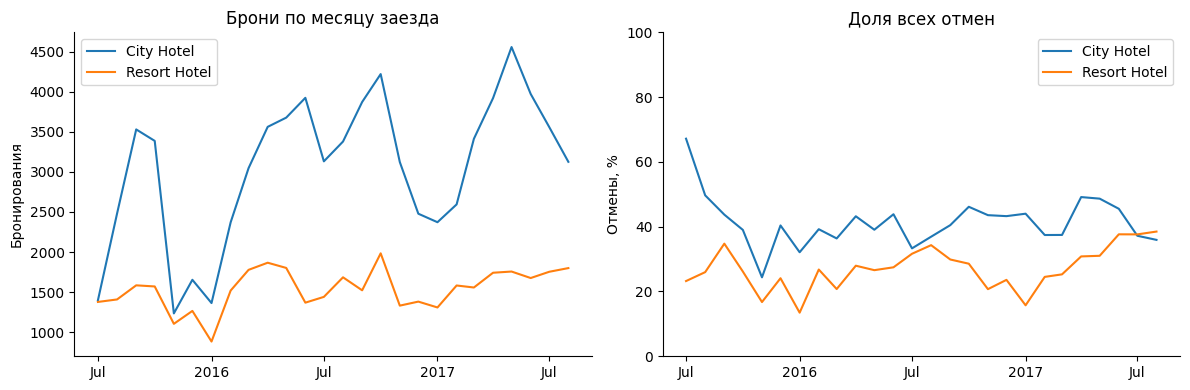

In [4]:
monthly = pd.read_csv(REPORTS / "monthly_all.csv", parse_dates=["month"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for hotel, group in monthly.groupby("hotel"):
    axes[0].plot(group.month, group.bookings, label=hotel)
    axes[1].plot(group.month, group.cancellation_rate * 100, label=hotel)
axes[0].set(title="Брони по месяцу заезда", ylabel="Бронирования")
axes[1].set(title="Доля всех отмен", ylabel="Отмены, %", ylim=(0, 100))
for ax in axes:
    locator = mdates.AutoDateLocator(minticks=4, maxticks=6)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.legend()
plt.tight_layout()
plt.show()

## Какие брони входят в задачу

На конец дня перед заездом бронь должна уже существовать и ещё не быть отменена. Поэтому оставляю lead_time ≥ 1 и исключаю отмены с reservation_status_date раньше даты заезда. Получается 70 908 броней, среди них 1 657 поздних отмен и незаездов — 2,34%.

reservation_status_date нужна для формирования этой выборки и проверки, когда исход стал известен. В признаки модели она не входит.

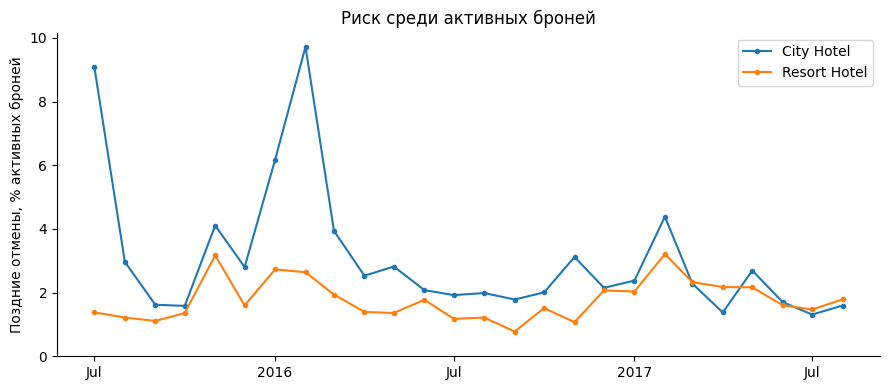

In [5]:
active = pd.read_csv(REPORTS / "monthly_active.csv", parse_dates=["month"])
fig, ax = plt.subplots()
for hotel, group in active.groupby("hotel"):
    ax.plot(
        group.month,
        group.cancellation_rate * 100,
        marker="o",
        markersize=3,
        label=hotel,
    )
locator = mdates.AutoDateLocator(minticks=5, maxticks=7)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.set(
    ylabel="Поздние отмены, % активных броней",
    title="Риск среди активных броней",
    ylim=(0, None),
)
ax.legend()
plt.tight_layout()
plt.show()

## Почему использую месяц заезда

Дата создания восстанавливается как arrival_date − lead_time. Но в выгрузку попали только заезды до конца августа 2017. У броней, созданных ближе к этому краю, длинный срок ожидания всё чаще выводит заезд за пределы набора. Из-за этого видимый lead_time уменьшается даже без изменения поведения клиентов. Поэтому сравнение моделей строю по месяцам заезда.

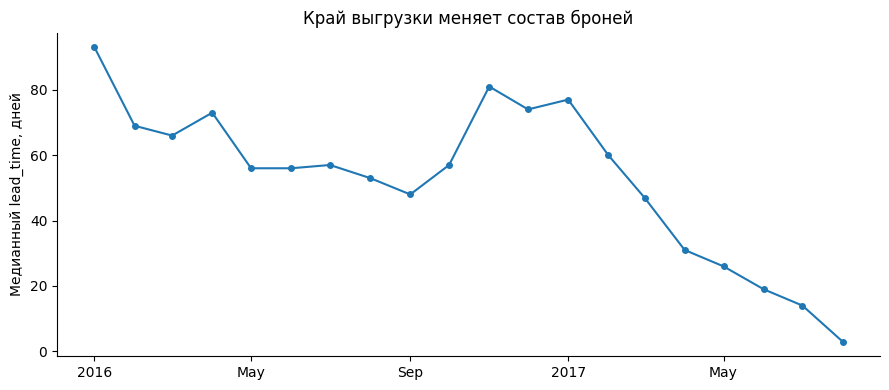

In [6]:
cohorts = pd.read_csv(REPORTS / "booking_cohorts.csv", parse_dates=["month"])
cohorts = cohorts.loc[cohorts.month >= "2016-01-01"]
fig, ax = plt.subplots()
ax.plot(cohorts.month, cohorts.median_lead_time, marker="o", markersize=4)
locator = mdates.AutoDateLocator(minticks=5, maxticks=7)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.set(ylabel="Медианный lead_time, дней", title="Край выгрузки меняет состав броней")
plt.tight_layout()
plt.show()

## Выводы

Объём бронирований и риск отмен меняются по времени и отличаются между отелями. Для проверки модели нужен последовательный временной эксперимент. Одного сравнения случайных train и test здесь недостаточно.

Поздние отмены встречаются гораздо реже всех отмен. Дальше буду смотреть Average Precision и долю найденных отмен при ограниченном списке проверок. Календарный рисунок в данных есть, но его пользу как признака ещё нужно проверить.